## Runner Notebook

### Prepare the GRCh37 gene annotation

In [19]:
source("R/part1.R")
prepare_part1_annotation()

In [20]:
required_results <- c(
  "COMPLETE.txt", "top_hit_per_gene.tsv", "chr22_cis_eqtl.tsv.gz",
  "chr22_matched_samples.tsv"
)
derived_dir <- "data/derived"
candidate_dirs <- c(
  file.path(derived_dir, "part1_grch37"),
  list.files(derived_dir, pattern = "^part1_grch37_notebook_chr22_", full.names = TRUE)
)
completed_dirs <- candidate_dirs[vapply(candidate_dirs, function(path) {
  all(file.exists(file.path(path, required_results)))
}, logical(1))]

if (length(completed_dirs)) {
  run_dir <- completed_dirs[[1]]
} else {
  run_dir <- tempfile("part1_grch37_notebook_chr22_", tmpdir = derived_dir)
  run_part1(run_dir, chromosomes = 22)
}

Extracting number of samples and rownames from 1000G.EUR.22.fam...

Extracting number of variants and colnames from 1000G.EUR.22.bim...



  chromosome n_genotype_samples n_matched_samples n_variants n_genes_attempted
1         22                489               344      17489               379
  n_genes_tested n_pairs_tested
1            379         175584


### Visualization of results

The boxplot shows IL17RA expression by genotype for the SNP with the lowest p-value in its GRCh37 cis window.

Extracting number of samples and rownames from 1000G.EUR.22.fam...

Extracting number of variants and colnames from 1000G.EUR.22.bim...



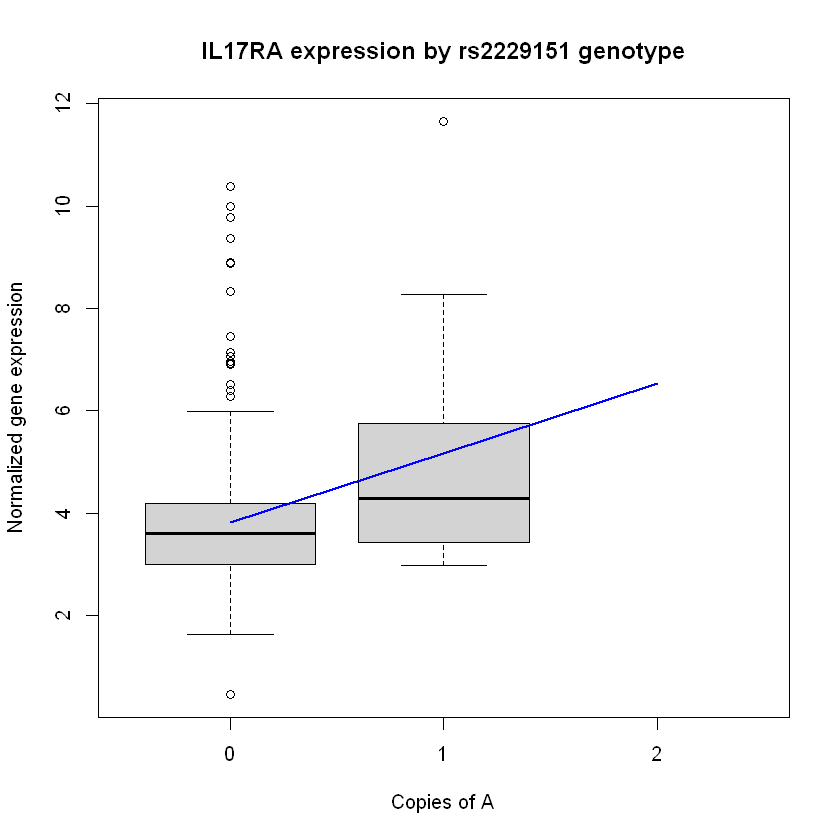

In [21]:
inputs <- read_part1_inputs(chromosomes = 22)
hits <- read.delim(file.path(run_dir, "top_hit_per_gene.tsv"))
snp_result <- hits[hits$gene_symbol == "IL17RA", ]

genotype_file <- file.path(part1_genotype_dir, "1000G.EUR.22.bed")
genotypes <- BEDMatrix::BEDMatrix(genotype_file, simple_names = TRUE)

sample_ids <- intersect(rownames(genotypes), inputs$sample_ids)
gene_row <- match(snp_result$gene_id, inputs$expression$ensembl_id)

dosage <- as.numeric(genotypes[sample_ids, snp_result$snp])
expression <- as.numeric(
  unlist(inputs$expression[gene_row, sample_ids], use.names = FALSE)
)

par(bg = "white")
boxplot(
  expression ~ factor(dosage, levels = 0:2),
  at = 0:2,
  xlab = paste("Copies of", snp_result$effect_allele),
  ylab = "Normalized gene expression",
  main = paste("IL17RA expression by", snp_result$snp, "genotype")
)

lines(
  0:2,
  snp_result$intercept + snp_result$beta * (0:2),
  col = "blue",
  lwd = 2
)

### Locus Zoom plot on Chromosome 22

rs2229151, chr 22: 17065844 - 18096583  [527 SNPs]

14 tracks needed to show all genes



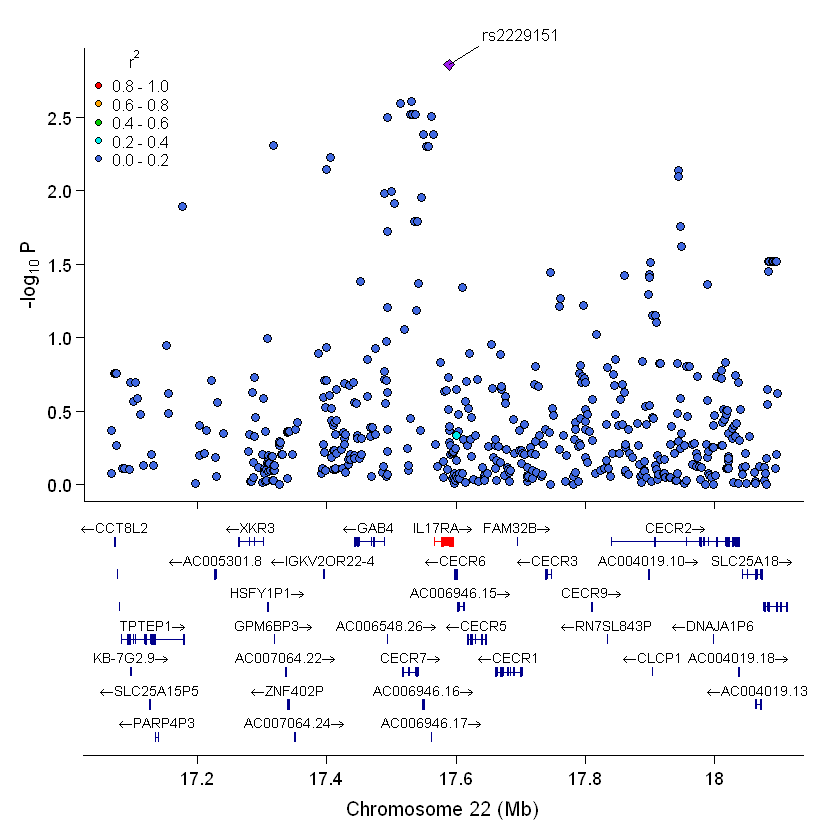

In [22]:
library(EnsDb.Hsapiens.v75)

results <- read.delim(file.path(run_dir, "chr22_cis_eqtl.tsv.gz"))
il17ra <- results[results$gene_symbol == "IL17RA", ]
samples <- read.delim(
  file.path(run_dir, "chr22_matched_samples.tsv"),
  colClasses = "character"
)

# Calculate LD with the SNP that has the lowest raw p-value.
lead_snp <- il17ra$snp[which.min(il17ra$p_value)]
dosages <- as.matrix(genotypes[samples$IID, il17ra$snp, drop = FALSE])
il17ra$ld_r2 <- as.numeric(cor(dosages, dosages[, lead_snp]))^2

il17ra_locus <- locuszoomr::locus(
  data = il17ra,
  seqname = "22",
  xrange = c(il17ra$window_start[1], il17ra$window_end[1]),
  ens_db = "EnsDb.Hsapiens.v75",
  chrom = "chromosome",
  pos = "snp_bp",
  p = "p_value",
  labs = "snp",
  index_snp = lead_snp,
  LD = "ld_r2"
)

par(bg = "white")
locuszoomr::locus_plot(
  il17ra_locus,
  highlight = "IL17RA",
  labels = "index",
  pcutoff = NULL
)